In [1]:
!pip -q install ucimlrepo

In [2]:
import os, warnings, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, classification_report, confusion_matrix
)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

# Create folders where project outputs will be saved.
PROJECT_DIR = "/content/Student_Performance_Project"
GRAPH_DIR = os.path.join(PROJECT_DIR, "Graphs")
REPORT_DIR = os.path.join(PROJECT_DIR, "Reports")
os.makedirs(GRAPH_DIR, exist_ok=True)
os.makedirs(REPORT_DIR, exist_ok=True)

print("Setup complete.")

Setup complete.


In [3]:
cluster_features = [c for c in ["age", "studytime", "failures", "absences"] if c in df.columns]
cluster_data = df[cluster_features].copy()

# Scale features because K-Means is sensitive to feature magnitude.
scaler = StandardScaler()
scaled_cluster_data = scaler.fit_transform(cluster_data)

kmeans = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
df["Cluster"] = kmeans.fit_predict(scaled_cluster_data)

# Understand the groups by comparing their average characteristics.
cluster_profile = df.groupby("Cluster")[cluster_features + ["G3"]].mean().round(2)
display(cluster_profile)

# PCA to reduce the scaled data to two dimensions.
pca = PCA(n_components=2, random_state=RANDOM_STATE)
pca_data = pca.fit_transform(scaled_cluster_data)

plt.figure(figsize=(7, 5))
plt.scatter(pca_data[:, 0], pca_data[:, 1], c=df["Cluster"], alpha=0.7)
plt.title("Student Groups Visualised with PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.tight_layout()
plt.savefig(os.path.join(GRAPH_DIR, "07_kmeans_pca_clusters.png"), dpi=150)
plt.show()

print("Explained variance by two components:",
      round(pca.explained_variance_ratio_.sum(), 3))

NameError: name 'df' is not defined

In [4]:
!pip install -q ucimlrepo

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Load Student Performance dataset
student_data = fetch_ucirepo(id=320)

# Create DataFrame
df = student_data.data.features.copy()

# Add final grade
df["G3"] = student_data.data.targets["G3"].values

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (649, 31)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,no,no,4,3,4,1,1,3,4,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,yes,no,5,3,3,1,1,3,2,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,yes,no,4,3,2,2,3,3,6,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,yes,yes,3,2,2,1,1,5,0,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,no,no,4,3,2,1,2,5,0,13


In [5]:
# Select clustering features
cluster_features = [
    c for c in ["age", "studytime", "failures", "absences"]
    if c in df.columns
]

# Create clustering dataset
cluster_data = df[cluster_features].copy()

# Scale the features
scaler = StandardScaler()
scaled_data = scaler.fit_transform(cluster_data)

# Apply K-Means clustering
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(scaled_data)

print("K-Means clustering completed!")
print(df[["Cluster"] + cluster_features].head())

print("\nCluster distribution:")
print(df["Cluster"].value_counts())

K-Means clustering completed!
   Cluster  age  studytime  failures  absences
0        2   18          2         0         4
1        2   17          2         0         2
2        1   15          2         0         6
3        2   15          3         0         0
4        2   16          2         0         0

Cluster distribution:
Cluster
2    331
1    237
0     81
Name: count, dtype: int64


In [6]:
# Reduce features to two dimensions
pca = PCA(n_components=2)

pca_data = pca.fit_transform(scaled_data)

# Create PCA DataFrame
pca_df = pd.DataFrame(
    pca_data,
    columns=["PC1", "PC2"]
)

pca_df["Cluster"] = df["Cluster"].values

print("PCA completed successfully!")

print(
    "Explained variance:",
    pca.explained_variance_ratio_
)

PCA completed successfully!
Explained variance: [0.36522512 0.25170997]


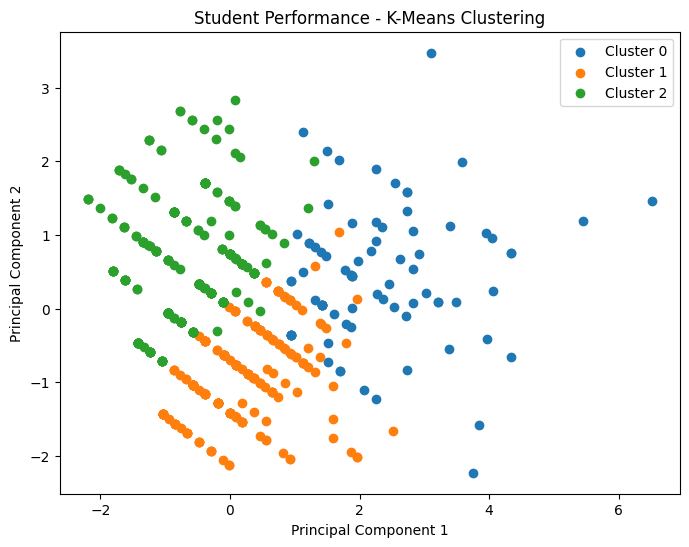

In [7]:
plt.figure(figsize=(8, 6))

for cluster in sorted(pca_df["Cluster"].unique()):
    cluster_points = pca_df[pca_df["Cluster"] == cluster]

    plt.scatter(
        cluster_points["PC1"],
        cluster_points["PC2"],
        label=f"Cluster {cluster}"
    )

plt.title("Student Performance - K-Means Clustering")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.show()

In [8]:
# Create a ZIP of generated project outputs for convenient download.
zip_path = "/content/Student_Performance_Project_outputs.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for root, dirs, files in os.walk(PROJECT_DIR):
        for file in files:
            full_path = os.path.join(root, file)
            arcname = os.path.relpath(full_path, PROJECT_DIR)
            zf.write(full_path, arcname)

print("Project output ZIP created:", zip_path)
print("In Colab, run the next cell to download it.")

Project output ZIP created: /content/Student_Performance_Project_outputs.zip
In Colab, run the next cell to download it.


In [9]:
from google.colab import files
files.download("/content/Student_Performance_Project_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>